# 01. Exploratory Data Analysis: E-Commerce A/B Test Results

**Project**: A/B Testing & Product Experimentation Analytics  
**Role**: Senior Experimentation Analyst / Data Scientist  
**Dataset**: E-commerce Website Landing Page Experiment (`ab_data.csv` and `countries.csv`)  
**Objective**: Audit data quality, identify instrumentation anomalies and tracking mismatches, establish clean cohorts, and explore baseline user conversion behavior across time and geographic segments.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules can be imported
sys.path.append(os.path.abspath(".."))

from src.data_loader import ensure_data_downloaded, load_raw_experiment_data, load_countries_data
from src.data_cleaning import audit_raw_data, clean_experiment_data

# Set visual style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["Segoe UI", "DejaVu Sans", "Arial"]


## 1. Data Ingestion and Provenance

We load the raw experiment records (`ab_data.csv`) and the geographic country mappings (`countries.csv`).
Each record represents a user visit with variant assignment and conversion outcome.


In [2]:
ensure_data_downloaded("../data/raw")
raw_df = load_raw_experiment_data("../data/raw/ab_data.csv")
countries_df = load_countries_data("../data/raw/countries.csv")

print(f"Raw Experiment Data Shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Countries Mapping Shape:    {countries_df.shape[0]:,} rows x {countries_df.shape[1]} columns")
raw_df.head()


Raw Experiment Data Shape: 294,478 rows x 5 columns
Countries Mapping Shape:    290,584 rows x 2 columns


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## 2. Data Dictionary & Schema Inspection

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `user_id` | `int64` | Unique visitor identifier |
| `timestamp` | `datetime64[ns]` | Date and UTC time of the webpage visit |
| `group` | `category` | Experimental condition (`control`, `treatment`) |
| `landing_page` | `category` | Rendered webpage version (`old_page`, `new_page`) |
| `converted` | `int64` | Binary conversion indicator (`0` = No conversion, `1` = Converted) |
| `country` | `category` | Geographic territory (`US`, `UK`, `CA`) |


In [3]:
raw_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[ns]
 2   group         294478 non-null  category      
 3   landing_page  294478 non-null  category      
 4   converted     294478 non-null  int64         
dtypes: category(2), datetime64[ns](1), int64(2)
memory usage: 7.3 MB


## 3. Data Quality Audit: Structural Inspection of Visitor Sessions

In web experimentation platforms, client caching, race conditions, and redirect misconfigurations frequently compromise raw telemetry.
We audit:
1. Missing or invalid outcomes (`converted` not in `{0, 1}`)
2. Unique visitor count vs. total record count
3. Visitor session frequency (single-visit vs. multi-visit users)
4. Conflicting variant assignments across sessions for the same visitor
5. Conflicting landing pages rendered across sessions for the same visitor
6. Row-level routing mismatches (`group == 'control'` on `new_page`, or `treatment` on `old_page`)


In [4]:
audit_rep = audit_raw_data(raw_df)

print("=== Comprehensive Data Quality Audit Report ===")
for k, v in audit_rep.to_dict().items():
    print(f"  {k:35s}: {v}")


=== Comprehensive Data Quality Audit Report ===
  total_raw_records                  : 294478
  unique_visitors                    : 290584
  single_visit_visitors              : 286690
  multi_visit_visitors               : 3894
  conflicting_group_visitors         : 1895
  conflicting_page_visitors          : 1998
  control_new_page_mismatch_rows     : 1928
  treatment_old_page_mismatch_rows   : 1965
  total_mismatch_rows                : 3893
  invalid_conversion_rows            : 0
  start_timestamp                    : 2017-01-02 13:42:05.378582
  end_timestamp                      : 2017-01-24 13:41:54.460509
  duration_days                      : 22.0


### Structural Breakdown of Multi-Session Visitors

We investigate the **3,894 visitors** who recorded more than one session:
- **1 visitor** (`user_id = 773192`) had 2 consistent sessions in `treatment` on `new_page`.
- **1,895 visitors** were logged under conflicting experimental groups (`control` in one session, `treatment` in another).
- **1,998 visitors** were served conflicting landing pages (`old_page` in one session, `new_page` in another).
- In total, **3,893 rows** represent routing mismatches where `group` and `landing_page` disagree.


In [5]:
crosstab_raw = pd.crosstab(raw_df["group"], raw_df["landing_page"], margins=True)
display(crosstab_raw)

# Identify mismatched rows
is_mismatch = (
    ((raw_df["group"] == "treatment") & (raw_df["landing_page"] == "old_page")) |
    ((raw_df["group"] == "control") & (raw_df["landing_page"] == "new_page"))
)
print(f"Total Mismatched Rows: {is_mismatch.sum():,} ({is_mismatch.mean()*100:.2f}% of raw records)")


landing_page,new_page,old_page,All
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
All,147239,147239,294478


Total Mismatched Rows: 3,893 (1.32% of raw records)


## 4. Cohort Cleaning & Methodological Framing

A common convention (e.g., in Udacity's benchmark analysis) is to filter out the 3,893 mismatched rows and retain the earliest visit for each user, producing a cohort of **290,584 unique visitors**.

> **Methodological Note**: Filtering out mismatched rows should NOT be claimed to "prevent contamination" or guarantee an unbiased causal estimate. Because users with routing errors may systematically differ from uncorrupted users, excluding them is an empirical benchmark rule that requires sensitivity validation across alternative specifications (Strictly Unambiguous, First-Touch Assignment Proxy, As-Treated).


In [6]:
clean_df, _ = clean_experiment_data(raw_df)

print(f"Pre-Cleaning Row Count:  {len(raw_df):,}")
print(f"Post-Cleaning Row Count: {len(clean_df):,}")
print(f"Unique Users in Clean:   {clean_df['user_id'].nunique():,}")
print(f"Data Retention Rate:     {(len(clean_df) / len(raw_df))*100:.2f}%")

# Verify zero mismatches remain in benchmark cohort
assert (
    ((clean_df["group"] == "control") & (clean_df["landing_page"] == "new_page")).sum() == 0
)
assert (
    ((clean_df["group"] == "treatment") & (clean_df["landing_page"] == "old_page")).sum() == 0
)
print("Data validation assertions passed: Benchmark cohort is filtered and reconciled.")


Pre-Cleaning Row Count:  294,478
Post-Cleaning Row Count: 290,584
Unique Users in Clean:   290,584
Data Retention Rate:     98.68%
Data validation assertions passed: Benchmark cohort is filtered and reconciled.


## 5. Group Distributions & Conversion Rates

We summarize the cleaned cohorts to observe group sizes, conversion volumes, and baseline conversion rates.


,group,Visitors,Conversions,Conversion_Rate,Conversion_Rate_Pct
0,control,145274,17489,0.120386,12.038630
1,treatment,145310,17264,0.118808,11.880807


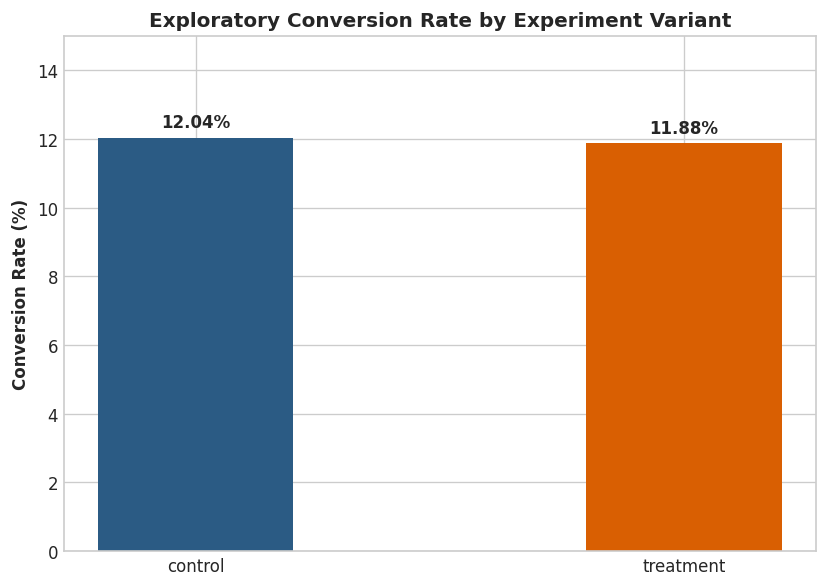

In [7]:
group_summary = clean_df.groupby("group", observed=False)["converted"].agg(
    Visitors="count",
    Conversions="sum",
    Conversion_Rate="mean"
).reset_index()

group_summary["Conversion_Rate_Pct"] = group_summary["Conversion_Rate"] * 100
display(group_summary)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(group_summary["group"], group_summary["Conversion_Rate_Pct"], color=["#2B5B84", "#D95F02"], width=0.4)
ax.set_ylabel("Conversion Rate (%)", fontweight="bold")
ax.set_title("Exploratory Conversion Rate by Experiment Variant", fontweight="bold")
ax.set_ylim(0, 15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.3, f"{yval:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


## 6. Temporal Patterns & Novelty Effect Exploration

A common pitfall in digital experimentation is the **novelty effect**, where users initially interact more (or less) with a new interface before reverting to baseline behavior.
We plot the daily conversion rates and visitor volume across all 23 days of the test.


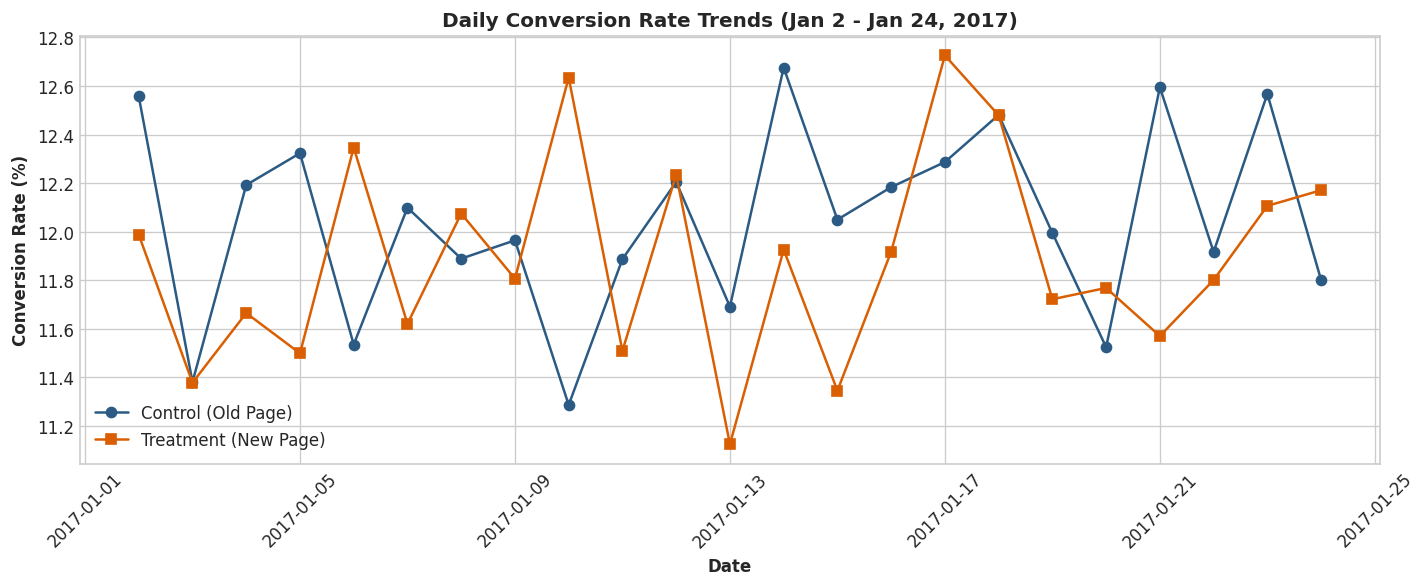

In [8]:
clean_df["date"] = pd.to_datetime(clean_df["timestamp"]).dt.date

daily_df = clean_df.groupby(["date", "group"], observed=False).agg(
    visitors=("converted", "count"),
    conversions=("converted", "sum"),
).reset_index()
daily_df["cr_pct"] = (daily_df["conversions"] / daily_df["visitors"]) * 100

ctrl_daily = daily_df[daily_df["group"] == "control"]
treat_daily = daily_df[daily_df["group"] == "treatment"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ctrl_daily["date"], ctrl_daily["cr_pct"], marker="o", color="#2B5B84", label="Control (Old Page)")
ax.plot(treat_daily["date"], treat_daily["cr_pct"], marker="s", color="#D95F02", label="Treatment (New Page)")
ax.set_title("Daily Conversion Rate Trends (Jan 2 - Jan 24, 2017)", fontweight="bold")
ax.set_ylabel("Conversion Rate (%)", fontweight="bold")
ax.set_xlabel("Date", fontweight="bold")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Geographic Segment Exploration

We merge the cleaned experiment records with the `countries.csv` dataset to check user representation and conversion behavior across territories.


,country,group,Visitors,Conversions,Conversion_Rate,CR_Pct
0,CA,control,7198,855,0.118783,11.878300
1,CA,treatment,7301,817,0.111902,11.190248
2,UK,control,36360,4364,0.120022,12.002200
3,UK,treatment,36106,4375,0.121171,12.117100
4,US,control,101716,12270,0.120630,12.062999
5,US,treatment,101903,12072,0.118466,11.846560


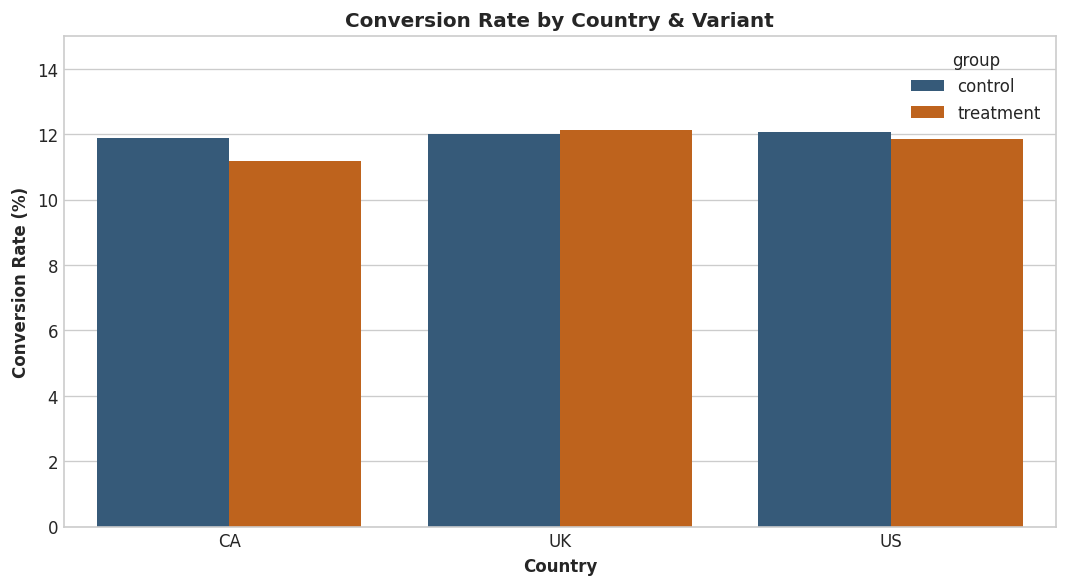

In [9]:
merged_df = clean_df.merge(countries_df, on="user_id", how="inner")

country_summary = merged_df.groupby(["country", "group"], observed=False).agg(
    Visitors=("converted", "count"),
    Conversions=("converted", "sum"),
    Conversion_Rate=("converted", "mean")
).reset_index()
country_summary["CR_Pct"] = country_summary["Conversion_Rate"] * 100
display(country_summary)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=country_summary, x="country", y="CR_Pct", hue="group", palette=["#2B5B84", "#D95F02"], ax=ax)
ax.set_title("Conversion Rate by Country & Variant", fontweight="bold")
ax.set_ylabel("Conversion Rate (%)", fontweight="bold")
ax.set_xlabel("Country", fontweight="bold")
ax.set_ylim(0, 15)
plt.tight_layout()
plt.show()


## 8. Summary of Exploratory Findings

1. **Instrumentation Quality**: 3,893 records (1.32%) contained routing mismatches. Structural inspection shows 1,895 users experienced conflicting group assignments and 1,998 users received conflicting landing pages.
2. **Benchmark Cohort**: Filtering out the 3,893 mismatched rows yields 290,584 unique visitors (145,274 control; 145,310 treatment).
3. **Conversion Baselines**: Control achieved 12.04% conversion rate; Treatment achieved 11.88% conversion rate.
4. **Temporal Stability**: Daily conversion rates oscillate consistently between 11% and 13% for both groups without evidence of extreme spikes or decay.
5. **Next Step**: Proceed to `02_experiment_analysis.ipynb` for formal statistical hypothesis testing, SRM validation, power analysis, sensitivity analysis across cohort definitions, and product decision-making.
